In [1]:
!pip -q install rasterio scikit-learn seaborn

In [2]:
import os
import glob
import random
import json
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_recall_fscore_support,
    jaccard_score,
    f1_score
)

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

assert tf.config.list_physical_devices("GPU"), (
    "GPU not detected. Select a T4 GPU in Colab runtime settings."
)

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.mount("/content/drive")

# CHANGE THIS to your actual dataset directory.
# It should contain the Sentinel-2 imagery and its corresponding masks.
DATA_ROOT = "/content/drive/MyDrive/Dataset"

print("Dataset directory exists:", os.path.isdir(DATA_ROOT))

if os.path.isdir(DATA_ROOT):
    for root, dirs, files in os.walk(DATA_ROOT):
        depth = root.replace(DATA_ROOT, "").count(os.sep)
        if depth <= 2:
            print(
                "  " * depth,
                os.path.basename(root) or root,
                f"({len(files)} files)"
            )

Mounted at /content/drive
Dataset directory exists: True
 Dataset (2 files)
   Sentinel1 (0 files)
     S1 (21684 files)
     Floodmaps (21620 files)
   Sentinel2 (0 files)
     Floodmaps (2675 files)
     S2 (2685 files)


In [4]:
from pathlib import Path
import os
import numpy as np
import rasterio

DATA_ROOT = "/content/drive/MyDrive/Dataset"

IMAGE_DIR = os.path.join(DATA_ROOT, "Sentinel2", "S2")
MASK_DIR = os.path.join(DATA_ROOT, "Sentinel2", "Floodmaps")

assert os.path.isdir(IMAGE_DIR), f"Missing: {IMAGE_DIR}"
assert os.path.isdir(MASK_DIR), f"Missing: {MASK_DIR}"

def list_tiffs(folder):
    return sorted(
        list(Path(folder).glob("*.tif")) +
        list(Path(folder).glob("*.tiff"))
    )

image_files = list_tiffs(IMAGE_DIR)
mask_files = list_tiffs(MASK_DIR)

print("Sentinel-2 images:", len(image_files))
print("Sentinel-2 masks:", len(mask_files))
print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)

Sentinel-2 images: 2685
Sentinel-2 masks: 2675
Image directory: /content/drive/MyDrive/Dataset/Sentinel2/S2
Mask directory: /content/drive/MyDrive/Dataset/Sentinel2/Floodmaps


In [5]:
mask_lookup = {p.name: p for p in mask_files}

pairs = [
    (img_path, mask_lookup[img_path.name])
    for img_path in image_files
    if img_path.name in mask_lookup
]

unmatched_images = [
    p.name for p in image_files
    if p.name not in mask_lookup
]

print("Matched image-mask pairs:", len(pairs))
print("Unmatched images:", len(unmatched_images))

if unmatched_images:
    print("Example unmatched filenames:", unmatched_images[:10])

assert len(pairs) > 0, "No matching image-mask pairs found."

# Inspect the first matched pair.
img_path, mask_path = pairs[0]

with rasterio.open(img_path) as src:
    sample_image = src.read()
    print("\nImage filename:", img_path.name)
    print("Image shape:", sample_image.shape)
    print("Image dtype:", sample_image.dtype)
    print("Image nodata:", src.nodata)
    print("Image min/max:", np.nanmin(sample_image), np.nanmax(sample_image))

with rasterio.open(mask_path) as src:
    sample_mask = src.read(1)
    print("\nMask filename:", mask_path.name)
    print("Mask shape:", sample_mask.shape)
    print("Mask dtype:", sample_mask.dtype)
    print("Mask nodata metadata:", src.nodata)
    print("Mask class values:", np.unique(sample_mask, return_counts=True))

assert sample_image.shape == (9, 128, 128), (
    "Expected a nine-band 128x128 Sentinel-2 tile. "
    "Check the selected image folder."
)

assert sample_mask.shape == (128, 128), (
    "Expected a 128x128 mask."
)

assert img_path.name == mask_path.name

Matched image-mask pairs: 2675
Unmatched images: 10
Example unmatched filenames: ['EMSR419_AOI05_03_09_1_2 (1).tif', 'EMSR422_AOI07_05_06_1_2 (1).tif', 'EMSR442_AOI06_4_2_2_1 (1).tif', 'EMSR467_AOI02_08_02_2_1 (1).tif', 'EMSR467_AOI03_08_05_2_2 (1).tif', 'EMSR470_AOI01_15_25_1_1 (1).tif', 'EMSR470_AOI01_19_21_2_1 (1).tif', 'EMSR470_AOI01_38_10_2_1 (1).tif', 'EMSR479_AOI02_33_24_1_2 (1).tif', 'EMSR554_AOI03_02_09_2_2 (1).tif']

Image filename: EMSR279_03ALFARO_17_16_1_1.tif
Image shape: (9, 128, 128)
Image dtype: float64
Image nodata: None
Image min/max: -0.4630564117431641 4.525833333333333

Mask filename: EMSR279_03ALFARO_17_16_1_1.tif
Mask shape: (128, 128)
Mask dtype: int32
Mask nodata metadata: 99.0
Mask class values: (array([0, 1, 2], dtype=int32), array([13675,   912,  1797]))


In [6]:
# Inspect several matched images and masks.
for img_path, mask_path in pairs[:5]:
    with rasterio.open(img_path) as src:
        image = src.read().astype(np.float32)

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    print("\nFile:", img_path.name)
    print(
        "Image range:",
        float(np.nanmin(image)),
        "to",
        float(np.nanmax(image))
    )
    print("Mask classes:", np.unique(mask))


File: EMSR279_03ALFARO_17_16_1_1.tif
Image range: -0.46305641531944275 to 4.5258331298828125
Mask classes: [0 1 2]

File: EMSR279_03ALFARO_17_16_2_1.tif
Image range: -0.4279581606388092 to 5.152500152587891
Mask classes: [0 1 2]

File: EMSR279_03ALFARO_17_16_2_2.tif
Image range: -0.37660348415374756 to 4.732500076293945
Mask classes: [0 1 2]

File: EMSR279_03ALFARO_19_18_1_2.tif
Image range: -0.4503370523452759 to 5.052499771118164
Mask classes: [0 1 2]

File: EMSR279_03ALFARO_19_18_2_2.tif
Image range: -0.4692656993865967 to 4.945127964019775
Mask classes: [0 2]


In [8]:
import rasterio
import numpy as np
import os

image_path = os.path.join(
    IMAGE_DIR, "EMSR279_03ALFARO_17_16_1_1.tif"
)
mask_path = os.path.join(
    MASK_DIR, "EMSR279_03ALFARO_17_16_1_1.tif"
)

with rasterio.open(image_path) as src:
    image = src.read()
    print("Image shape:", image.shape)
    print("Image dtype:", image.dtype)
    print("Band descriptions:", src.descriptions)
    print("Image nodata:", src.nodata)
    print("Band-wise min:", np.nanmin(image, axis=(1, 2)))
    print("Band-wise max:", np.nanmax(image, axis=(1, 2)))
    print("Band-wise mean:", np.nanmean(image, axis=(1, 2)))

with rasterio.open(mask_path) as src:
    mask = src.read(1)
    print("\nMask nodata:", src.nodata)
    print("Mask dtype:", mask.dtype)
    print("Mask unique values and counts:")
    print(np.unique(mask, return_counts=True))

Image shape: (9, 128, 128)
Image dtype: float64
Band descriptions: (None, None, None, None, None, None, None, None, None)
Image nodata: None
Band-wise min: [-0.27083333 -0.14666667 -0.1925      0.08345444 -0.12702384 -0.08409177
 -0.1275     -0.42266468 -0.46305641]
Band-wise max: [1.015      1.04333333 1.4225     1.70275411 3.61823934 4.40569539
 4.52583333 2.90744263 2.04445353]
Band-wise mean: [0.10283834 0.39673854 0.44430262 0.81043903 1.33992498 1.51633869
 1.56363327 0.78308642 0.36686928]

Mask nodata: 99.0
Mask dtype: int32
Mask unique values and counts:
(array([0, 1, 2], dtype=int32), array([13675,   912,  1797]))


In [9]:
import os
import numpy as np
import rasterio

sample_files = image_files[:20]

for path in sample_files:
    with rasterio.open(path) as src:
        img = src.read().astype(np.float32)

    print(
        os.path.basename(path),
        "| min:", round(float(np.nanmin(img)), 4),
        "| max:", round(float(np.nanmax(img)), 4),
        "| mean:", round(float(np.nanmean(img)), 4)
    )

EMSR279_03ALFARO_17_16_1_1.tif | min: -0.4631 | max: 4.5258 | mean: 0.8138
EMSR279_03ALFARO_17_16_2_1.tif | min: -0.428 | max: 5.1525 | mean: 1.0058
EMSR279_03ALFARO_17_16_2_2.tif | min: -0.3766 | max: 4.7325 | mean: 0.8365
EMSR279_03ALFARO_19_18_1_2.tif | min: -0.4503 | max: 5.0525 | mean: 0.9034
EMSR279_03ALFARO_19_18_2_2.tif | min: -0.4693 | max: 4.9451 | mean: 1.1079
EMSR279_03ALFARO_19_19_1_1.tif | min: -0.3831 | max: 3.8592 | mean: 0.4419
EMSR279_03ALFARO_19_19_1_2.tif | min: -0.4714 | max: 2.3233 | mean: 0.5807
EMSR279_03ALFARO_19_19_2_1.tif | min: -0.3211 | max: 5.075 | mean: 0.9043
EMSR279_03ALFARO_19_19_2_2.tif | min: -0.395 | max: 4.1929 | mean: 0.6481
EMSR279_04TUDELA_01_03_2_2.tif | min: -0.4415 | max: 4.6792 | mean: 0.9266
EMSR279_04TUDELA_05_04_1_2.tif | min: -0.5366 | max: 4.4975 | mean: 0.9725
EMSR279_04TUDELA_05_04_2_2.tif | min: -0.433 | max: 4.4617 | mean: 1.159
EMSR279_04TUDELA_06_07_1_1.tif | min: -0.5479 | max: 4.8417 | mean: 0.7204
EMSR279_04TUDELA_06_07_1_2.tif

In [10]:
import os
import numpy as np
import rasterio

# Use matched image paths from Cell 4/5
sample_paths = image_files[:100]

band_mins = []
band_maxs = []
band_means = []

for path in sample_paths:
    with rasterio.open(path) as src:
        img = src.read().astype(np.float32)

    band_mins.append(np.nanmin(img, axis=(1, 2)))
    band_maxs.append(np.nanmax(img, axis=(1, 2)))
    band_means.append(np.nanmean(img, axis=(1, 2)))

band_mins = np.asarray(band_mins)
band_maxs = np.asarray(band_maxs)
band_means = np.asarray(band_means)

for b in range(9):
    print(
        f"Band {b + 1}: "
        f"min={band_mins[:, b].min():.4f}, "
        f"max={band_maxs[:, b].max():.4f}, "
        f"mean={band_means[:, b].mean():.4f}"
    )

Band 1: min=-0.2933, max=5.9050, mean=0.3203
Band 2: min=-0.2517, max=5.9992, mean=0.6145
Band 3: min=-0.2808, max=6.3108, mean=0.6640
Band 4: min=-0.3108, max=5.9316, mean=0.9637
Band 5: min=-0.4024, max=5.9004, mean=1.5192
Band 6: min=-0.4354, max=5.9505, mean=1.7393
Band 7: min=-0.2808, max=6.3033, mean=1.7621
Band 8: min=-0.8427, max=6.4922, mean=0.9660
Band 9: min=-0.8230, max=6.3472, mean=0.5378


In [11]:
# incorrect code
import os
import numpy as np
import rasterio
from tqdm.auto import tqdm

# Paths from previous cells
IMAGE_DIR = "/content/drive/MyDrive/Dataset/Sentinel2/S2"
MASK_DIR = "/content/drive/MyDrive/Dataset/Sentinel2/Floodmaps"

# Match images and masks by filename
image_files = sorted([
    os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".tif", ".tiff"))
])

mask_files = {
    f: os.path.join(MASK_DIR, f)
    for f in os.listdir(MASK_DIR)
    if f.lower().endswith((".tif", ".tiff"))
}

matched_pairs = [
    (img_path, mask_files[os.path.basename(img_path)])
    for img_path in image_files
    if os.path.basename(img_path) in mask_files
]

print("Matched image-mask pairs:", len(matched_pairs))

# IMPORTANT:
# This mapping assumes classes 1 and 2 are both water-related.
# Verify this against the dataset's documented mask legend first.
WATER_CLASSES = {1, 2}
BACKGROUND_CLASSES = {0}
NODATA_VALUE = 99
MIN_WATER_FRACTION = 0.01

X_list = []
Y_list = []
kept_files = []

skipped_nodata = 0
skipped_invalid = 0
skipped_low_water = 0
skipped_unexpected_classes = 0

for img_path, mask_path in tqdm(matched_pairs):
    try:
        with rasterio.open(img_path) as src:
            image = src.read().astype(np.float32)

        with rasterio.open(mask_path) as src:
            mask = src.read(1)

        # Expected shapes: image (9, 128, 128), mask (128, 128)
        if image.shape != (9, 128, 128) or mask.shape != (128, 128):
            skipped_invalid += 1
            continue

        # Exclude mask NoData and non-finite pixels
        valid_mask = (mask != NODATA_VALUE) & np.isfinite(mask)
        valid_image = np.all(np.isfinite(image), axis=0)

        # If the mask contains unexpected classes, skip for inspection
        observed = set(np.unique(mask[valid_mask]).tolist())
        allowed = WATER_CLASSES | BACKGROUND_CLASSES

        if not observed.issubset(allowed):
            skipped_unexpected_classes += 1
            continue

        # Reject the whole tile if any pixel is invalid
        if not np.all(valid_mask) or not np.all(valid_image):
            skipped_nodata += 1
            continue

        # Convert to binary mask
        binary_mask = np.isin(mask, list(WATER_CLASSES)).astype(np.uint8)

        water_fraction = float(binary_mask.mean())
        if water_fraction <= MIN_WATER_FRACTION:
            skipped_low_water += 1
            continue

        # CHW -> HWC; no 400-1600 scaling
        image = np.transpose(image, (1, 2, 0))

        X_list.append(image.astype(np.float32))
        Y_list.append(binary_mask)
        kept_files.append(os.path.basename(img_path))

    except Exception as e:
        print(f"Skipping {os.path.basename(img_path)}: {e}")
        skipped_invalid += 1

if not X_list:
    raise ValueError(
        "No valid tiles were retained. Check paths, mask classes, and NoData."
    )

X = np.stack(X_list).astype(np.float32)
Y = np.stack(Y_list).astype(np.uint8)

print("\nPreprocessing complete")
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("X dtype:", X.dtype)
print("Y dtype:", Y.dtype)
print("X range:", float(X.min()), "to", float(X.max()))
print("Mask classes:", np.unique(Y))
print("Tiles retained:", len(X))
print("Skipped due to NoData:", skipped_nodata)
print("Skipped due to invalid shape/read:", skipped_invalid)
print("Skipped due to low water coverage:", skipped_low_water)
print("Skipped due to unexpected mask classes:", skipped_unexpected_classes)


Matched image-mask pairs: 2675


  0%|          | 0/2675 [00:00<?, ?it/s]


Preprocessing complete
X shape: (1997, 128, 128, 9)
Y shape: (1997, 128, 128)
X dtype: float32
Y dtype: uint8
X range: -1.538031816482544 to 15.239999771118164
Mask classes: [0 1]
Tiles retained: 1997
Skipped due to NoData: 5
Skipped due to invalid shape/read: 0
Skipped due to low water coverage: 0
Skipped due to unexpected mask classes: 673


In [12]:

import os
import numpy as np
import rasterio
from collections import Counter

class_counts = Counter()
tiles_by_class = Counter()
examples_by_class = {}

for img_path, mask_path in matched_pairs:
    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        value = int(value)
        class_counts[value] += int(count)
        tiles_by_class[value] += 1

        if value not in examples_by_class:
            examples_by_class[value] = []

        if len(examples_by_class[value]) < 3:
            examples_by_class[value].append(os.path.basename(mask_path))

print("Mask pixel counts across matched pairs:")
for value, count in sorted(class_counts.items()):
    print(
        f"Class {value}: {count:,} pixels; "
        f"present in {tiles_by_class[value]} tiles"
    )

print("\nExample files for each class:")
for value, files in sorted(examples_by_class.items()):
    print(f"Class {value}: {files}")


Mask pixel counts across matched pairs:
Class 0: 31,739,964 pixels; present in 2650 tiles
Class 1: 9,865,084 pixels; present in 2606 tiles
Class 2: 570,702 pixels; present in 1676 tiles
Class 3: 853,493 pixels; present in 326 tiles
Class 4: 141,386 pixels; present in 295 tiles
Class 5: 656,571 pixels; present in 521 tiles

Example files for each class:
Class 0: ['EMSR279_03ALFARO_17_16_1_1.tif', 'EMSR279_03ALFARO_17_16_2_1.tif', 'EMSR279_03ALFARO_17_16_2_2.tif']
Class 1: ['EMSR279_03ALFARO_17_16_1_1.tif', 'EMSR279_03ALFARO_17_16_2_1.tif', 'EMSR279_03ALFARO_17_16_2_2.tif']
Class 2: ['EMSR279_03ALFARO_17_16_1_1.tif', 'EMSR279_03ALFARO_17_16_2_1.tif', 'EMSR279_03ALFARO_17_16_2_2.tif']
Class 3: ['EMSR279_05ZARAGOZA_04_07_2_2.tif', 'EMSR279_05ZARAGOZA_06_09_1_1.tif', 'EMSR279_05ZARAGOZA_06_09_2_1.tif']
Class 4: ['EMSR279_04TUDELA_05_04_2_2.tif', 'EMSR279_04TUDELA_14_13_1_1.tif', 'EMSR279_04TUDELA_14_13_2_1.tif']
Class 5: ['EMSR279_04TUDELA_05_04_2_2.tif', 'EMSR279_04TUDELA_14_13_2_2.tif', '

In [13]:
# correct code
import os
import numpy as np
import rasterio
from tqdm.auto import tqdm

IMAGE_DIR = "/content/drive/MyDrive/Dataset/Sentinel2/S2"
MASK_DIR = "/content/drive/MyDrive/Dataset/Sentinel2/Floodmaps"

image_files = sorted([
    os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".tif", ".tiff"))
])

mask_files = {
    f: os.path.join(MASK_DIR, f)
    for f in os.listdir(MASK_DIR)
    if f.lower().endswith((".tif", ".tiff"))
}

matched_pairs = [
    (img_path, mask_files[os.path.basename(img_path)])
    for img_path in image_files
    if os.path.basename(img_path) in mask_files
]

print("Matched image-mask pairs:", len(matched_pairs))

VALID_CLASSES = {0, 1, 2, 3, 4, 5}
NODATA_VALUE = 99
MIN_WATER_FRACTION = 0.01

X_list, Y_list, kept_files = [], [], []

skipped_nodata = 0
skipped_invalid = 0
skipped_low_water = 0
skipped_unexpected_classes = 0

for img_path, mask_path in tqdm(matched_pairs):
    try:
        with rasterio.open(img_path) as src:
            image = src.read().astype(np.float32)

        with rasterio.open(mask_path) as src:
            mask = src.read(1)

        if image.shape != (9, 128, 128) or mask.shape != (128, 128):
            skipped_invalid += 1
            continue

        if not np.all(np.isfinite(image)):
            skipped_invalid += 1
            continue

        # Exclude tiles containing NoData or unexpected mask values.
        unique_classes = set(np.unique(mask).tolist())

        if NODATA_VALUE in unique_classes:
            skipped_nodata += 1
            continue

        if not unique_classes.issubset(VALID_CLASSES):
            skipped_unexpected_classes += 1
            continue

        # Binary remapping: 0 -> background; 1-5 -> water.
        binary_mask = np.isin(mask, [1, 2, 3, 4, 5]).astype(np.uint8)

        water_fraction = float(binary_mask.mean())
        if water_fraction <= MIN_WATER_FRACTION:
            skipped_low_water += 1
            continue

        # Convert (bands, height, width) to (height, width, bands).
        image = np.transpose(image, (1, 2, 0))

        X_list.append(image)
        Y_list.append(binary_mask)
        kept_files.append(os.path.basename(img_path))

    except Exception as e:
        print(f"Skipping {os.path.basename(img_path)}: {e}")
        skipped_invalid += 1

if not X_list:
    raise ValueError("No valid tiles retained. Check the dataset and mask values.")

X = np.stack(X_list).astype(np.float32)
Y = np.stack(Y_list).astype(np.uint8)

print("\nCorrected preprocessing complete")
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Image range:", float(X.min()), "to", float(X.max()))
print("Mask classes:", np.unique(Y))
print("Tiles retained:", len(X))
print("Skipped due to NoData:", skipped_nodata)
print("Skipped due to invalid shape/pixels/read:", skipped_invalid)
print("Skipped due to low water coverage:", skipped_low_water)
print("Skipped due to unexpected classes:", skipped_unexpected_classes)


Matched image-mask pairs: 2675


  0%|          | 0/2675 [00:00<?, ?it/s]


Corrected preprocessing complete
X shape: (2665, 128, 128, 9)
Y shape: (2665, 128, 128)
Image range: -1.5484994649887085 to 15.239999771118164
Mask classes: [0 1]
Tiles retained: 2665
Skipped due to NoData: 0
Skipped due to invalid shape/pixels/read: 10
Skipped due to low water coverage: 0
Skipped due to unexpected classes: 0


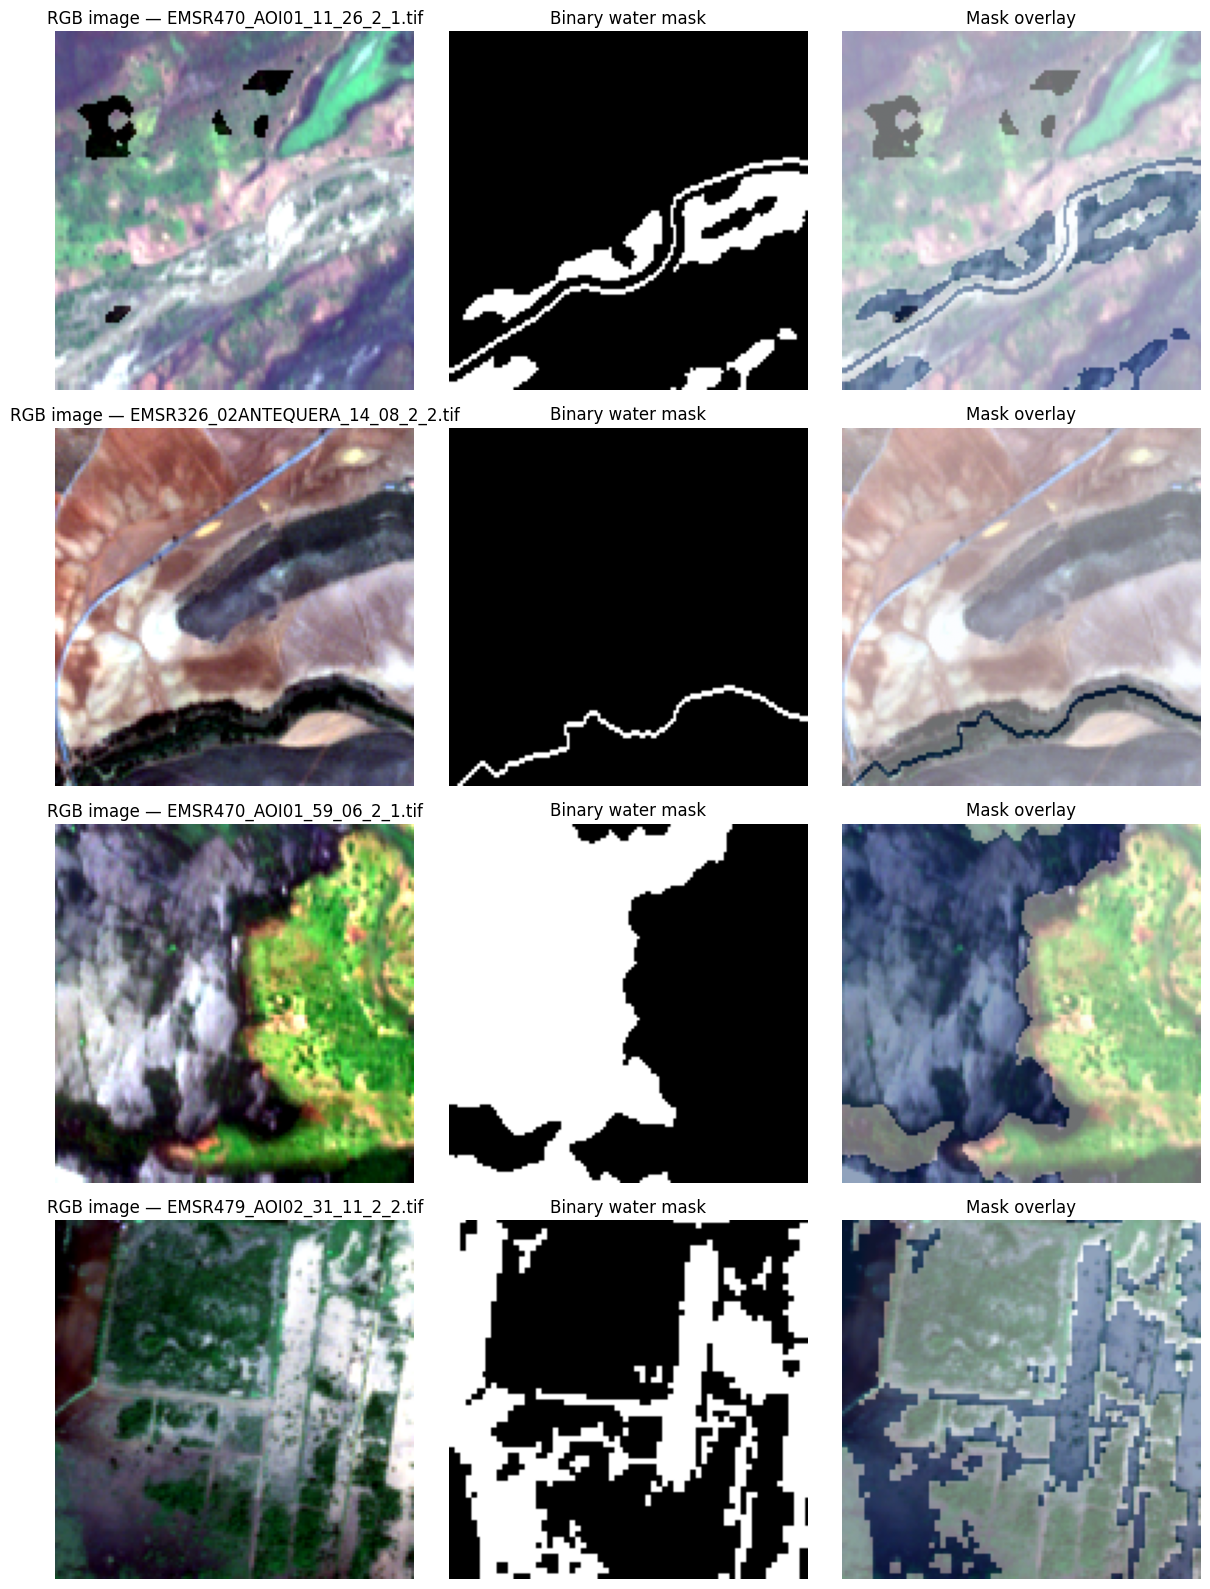

Water pixel percentage: 27.622 %


In [14]:

import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(42)
indices = rng.choice(len(X), size=min(4, len(X)), replace=False)

fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))

if len(indices) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, idx in enumerate(indices):
    image = X[idx]
    mask = Y[idx]

    # Sentinel-2 band order in the dataset:
    # B2, B3, B4, B5, B6, B7, B8, B11, B12
    # Display B4, B3, B2 as an RGB composite.
    rgb = image[:, :, [2, 1, 0]]

    # Percentile stretch is for visualization only.
    lo = np.percentile(rgb, 2, axis=(0, 1), keepdims=True)
    hi = np.percentile(rgb, 98, axis=(0, 1), keepdims=True)
    rgb = np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"RGB image — {kept_files[idx]}")

    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Binary water mask")

    axes[row, 2].imshow(rgb)
    axes[row, 2].imshow(mask, cmap="Blues", alpha=0.45, vmin=0, vmax=1)
    axes[row, 2].set_title("Mask overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Water pixel percentage:", round(float(Y.mean() * 100), 3), "%")


In [15]:

from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(X))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.20, random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42
)

X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)


Train: (2132, 128, 128, 9) (2132, 128, 128)
Validation: (266, 128, 128, 9) (266, 128, 128)
Test: (267, 128, 128, 9) (267, 128, 128)


In [16]:

import numpy as np
import tensorflow as tf

# Calculate per-band statistics from training images only.
# Arrays have shape: (samples, height, width, bands)
band_mean = X_train.mean(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)
band_std = X_train.std(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)

# Avoid division by zero for any constant band.
band_std = np.maximum(band_std, 1e-6)

print("Per-band training means:", band_mean)
print("Per-band training stds:", band_std)

# Apply identical training statistics to all splits.
X_train_norm = ((X_train - band_mean) / band_std).astype(np.float32)
X_val_norm = ((X_val - band_mean) / band_std).astype(np.float32)
X_test_norm = ((X_test - band_mean) / band_std).astype(np.float32)

print("\nNormalized data:")
print("Train:", X_train_norm.shape,
      "range:", float(X_train_norm.min()), "to", float(X_train_norm.max()))
print("Validation:", X_val_norm.shape)
print("Test:", X_test_norm.shape)

# Keep masks as integer class IDs: 0=background, 1=water.
Y_train = Y_train.astype(np.int32)
Y_val = Y_val.astype(np.int32)
Y_test = Y_test.astype(np.int32)

BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train_norm, Y_train)
).shuffle(1024, seed=42).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val_norm, Y_val)
).batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test_norm, Y_test)
).batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("\nTensorFlow datasets ready.")
print("GPU devices:", tf.config.list_physical_devices("GPU"))


Per-band training means: [0.528149   0.7723452  0.76478237 1.0460594  1.485518   1.6707981
 1.6686339  1.193631   0.7837061 ]
Per-band training stds: [0.4051415  0.4743622  0.5636837  0.52634066 0.7777099  0.91898334
 0.9513474  0.80562496 0.61943424]

Normalized data:
Train: (2132, 128, 128, 9) range: -3.7650575637817383 to 36.312870025634766
Validation: (266, 128, 128, 9)
Test: (267, 128, 128, 9)

TensorFlow datasets ready.
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# **U-NET Model**

In [17]:

import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(x, filters, dropout_rate=0.0):
    x = layers.Conv2D(
        filters, 3, padding="same", kernel_initializer="he_normal"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters, 3, padding="same", kernel_initializer="he_normal"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    return x

def build_unet(input_shape=(128, 128, 9), num_classes=2):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128, dropout_rate=0.1)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256, dropout_rate=0.1)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck
    c5 = conv_block(p4, 512, dropout_rate=0.2)

    # Decoder
    u6 = layers.Conv2DTranspose(256, 2, strides=2, padding="same")(c5)
    u6 = layers.Concatenate()([u6, c4])
    c6 = conv_block(u6, 256)

    u7 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(c6)
    u7 = layers.Concatenate()([u7, c3])
    c7 = conv_block(u7, 128)

    u8 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c7)
    u8 = layers.Concatenate()([u8, c2])
    c8 = conv_block(u8, 64)

    u9 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c8)
    u9 = layers.Concatenate()([u9, c1])
    c9 = conv_block(u9, 32)

    outputs = layers.Conv2D(
        num_classes, kernel_size=1, activation="softmax"
    )(c9)

    return Model(inputs, outputs, name="Sentinel2_UNet_Baseline")

model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

model.summary()


Model: "Sentinel2_UNet_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 9)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      2,624 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_4[0][0]  

 Total params: 7,773,634 (29.65 MB)

 Trainable params: 7,767,746 (29.63 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [18]:

import os
import tensorflow as tf

OUTPUT_DIR = "/content/drive/MyDrive/STURM_Sentinel2_Baseline"
os.makedirs(OUTPUT_DIR, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(OUTPUT_DIR, "best_unet.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(OUTPUT_DIR, "training_history.csv")
    )
]

EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/30
267/267 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - loss: 0.3506 - sparse_categorical_accuracy: 0.8572
Epoch 1: val_loss improved from None to 0.40406, saving model to /content/drive/MyDrive/STURM_Sentinel2_Baseline/best_unet.keras

Epoch 1: finished saving model to /content/drive/MyDrive/STURM_Sentinel2_Baseline/best_unet.keras
267/267 ━━━━━━━━━━━━━━━━━━━━ 101s 193ms/step - loss: 0.3129 - sparse_categorical_accuracy: 0.8777 - val_loss: 0.4041 - val_sparse_categorical_accuracy: 0.8971 - learning_rate: 0.0010
Epoch 2/30
266/267 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.2772 - sparse_categorical_accuracy: 0.8921
Epoch 2: val_loss improved from 0.40406 to 0.24542, saving model to /content/drive/MyDrive/STURM_Sentinel2_Baseline/best_unet.keras

Epoch 2: finished saving model to /content/drive/MyDrive/STURM_Sentinel2_Baseline/best_unet.keras
267/267 ━━━━━━━━━━━━━━━━━━━━ 18s 69ms/step - loss: 0.2846 - sparse_categorical_accuracy: 0.8893 - val_loss: 0.2454 - val_sparse_categorical_accur

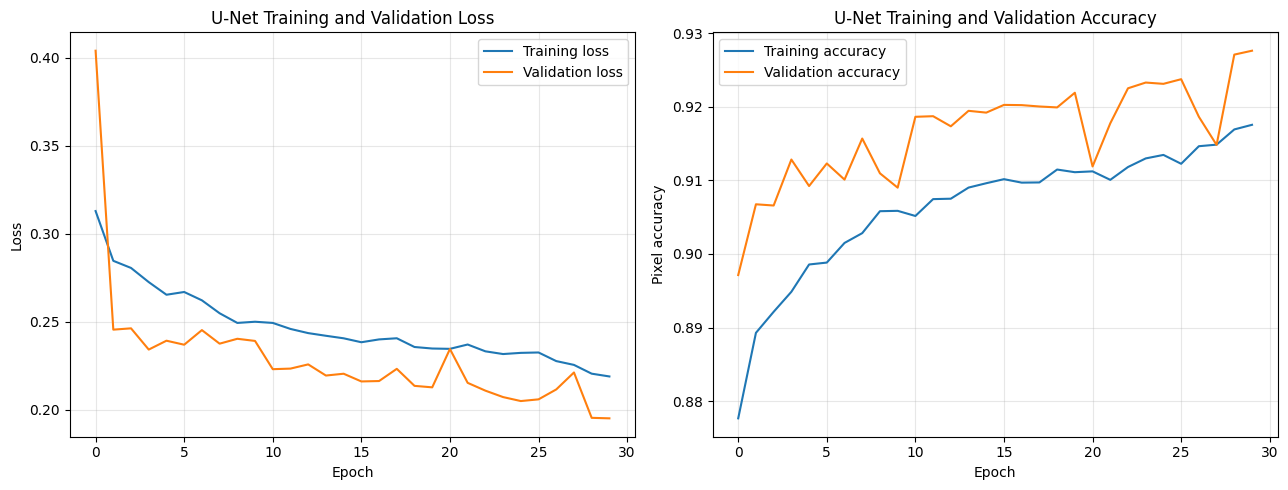

In [19]:

import matplotlib.pyplot as plt
import os

OUTPUT_DIR = "/content/drive/MyDrive/STURM_Sentinel2_Baseline"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss curves
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("U-Net Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(
    history.history["sparse_categorical_accuracy"],
    label="Training accuracy"
)
axes[1].plot(
    history.history["val_sparse_categorical_accuracy"],
    label="Validation accuracy"
)
axes[1].set_title("U-Net Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Pixel accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "training_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [20]:

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    jaccard_score
)

OUTPUT_DIR = "/content/drive/MyDrive/STURM_Sentinel2_Baseline"
MODEL_PATH = os.path.join(OUTPUT_DIR, "best_unet.keras")

# Load the best validation-loss checkpoint
best_model = tf.keras.models.load_model(MODEL_PATH)

# Predict class probabilities and convert to class labels
probabilities = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=-1)

# Flatten pixels for metric calculation
y_true_flat = Y_test.reshape(-1)
y_pred_flat = y_pred.reshape(-1)

accuracy = accuracy_score(y_true_flat, y_pred_flat)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true_flat,
    y_pred_flat,
    labels=[0, 1],
    zero_division=0
)

iou = jaccard_score(
    y_true_flat,
    y_pred_flat,
    labels=[0, 1],
    average=None,
    zero_division=0
)

cm = confusion_matrix(y_true_flat, y_pred_flat, labels=[0, 1])

print("\nTEST SET RESULTS")
print("=" * 50)
print(f"Pixel accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Water precision: {precision[1]:.4f}")
print(f"Water recall:    {recall[1]:.4f}")
print(f"Water F1-score:  {f1[1]:.4f}")
print(f"Water IoU:       {iou[1]:.4f}")
print(f"Background IoU:  {iou[0]:.4f}")
print(f"Macro F1-score:  {np.mean(f1):.4f}")

print("\nClassification report:")
print(classification_report(
    y_true_flat,
    y_pred_flat,
    labels=[0, 1],
    target_names=["Background", "Water"],
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows=true, columns=predicted):")
print(cm)

# Save results
metrics = {
    "test_pixel_accuracy": float(accuracy),
    "background_precision": float(precision[0]),
    "background_recall": float(recall[0]),
    "background_f1": float(f1[0]),
    "background_iou": float(iou[0]),
    "water_precision": float(precision[1]),
    "water_recall": float(recall[1]),
    "water_f1": float(f1[1]),
    "water_iou": float(iou[1]),
    "macro_f1": float(np.mean(f1))
}

with open(os.path.join(OUTPUT_DIR, "test_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame(
    cm,
    index=["True background", "True water"],
    columns=["Predicted background", "Predicted water"]
).to_csv(os.path.join(OUTPUT_DIR, "confusion_matrix.csv"))

print("\nSaved test metrics and confusion matrix to:", OUTPUT_DIR)


34/34 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step

TEST SET RESULTS
Pixel accuracy: 0.9253 (92.53%)
Water precision: 0.8750
Water recall:    0.8367
Water F1-score:  0.8554
Water IoU:       0.7474
Background IoU:  0.9042
Macro F1-score:  0.9025

Classification report:
              precision    recall  f1-score   support

  Background     0.9423    0.9572    0.9497   3219844
       Water     0.8750    0.8367    0.8554   1154684

    accuracy                         0.9253   4374528
   macro avg     0.9087    0.8969    0.9025   4374528
weighted avg     0.9246    0.9253    0.9248   4374528

Confusion matrix (rows=true, columns=predicted):
[[3081886  137958]
 [ 188616  966068]]

Saved test metrics and confusion matrix to: /content/drive/MyDrive/STURM_Sentinel2_Baseline
